# Arena Caro · L1–L8 và phân tích nước đi

**Run All** mở hai bộ dữ liệu có sẵn: 20 ván L7–L8 từ lượt huấn luyện L8 và giải arena cũ từ L1 đến các bản L5.
Hai bộ có thành phần và ngân sách khác nhau nên có bảng và biểu đồ riêng.

- Phần L7–L8 cho biết tác tử nào thắng khi đổi màu, lợi thế X/O và các nước đi đáng chú ý.
- Phần arena so sánh các tác tử qua ma trận đối đầu, bảng xếp hạng, thắng/hòa/thua, lợi thế X, độ dài ván và điểm tích lũy.
- Bật `RUN_ARENA` trong phần 2 để đánh giá L1–L8 trên cùng khai cuộc và có thêm biểu đồ thời gian. Chọn kernel `.venv`.

## 1. L7 đấu L8

Mỗi khai cuộc được chơi hai lần: L8 cầm X ở một ván, cầm O ở ván kia.
X đi trước trên bàn cờ. Sau khai cuộc có sẵn, tác tử được gọi đầu tiên có thể cầm O nếu số nước khai cuộc là lẻ.
L7 dùng mạng L5. L8 dùng `best.pt` ở vòng 37. Bật `RUN_NEW` để chạy riêng cặp này.

In [1]:
from collections import Counter, defaultdict
from datetime import datetime
from pathlib import Path
import hashlib
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from caro.engine import CaroGame, N, iter_bits, winning_squares

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "caro").is_dir() and (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục CaroGame hoặc thư mục con.")

RUN_NEW = False
READ_RUN = None               # tên thư mục đã chạy, nếu muốn mở lại ván mới
DEVICE = "auto"                # đổi thành "cuda" để yêu cầu GPU khi chạy trong terminal/Jupyter
BACKEND = "auto"               # "native" yêu cầu đã build Cython
N_OPENINGS = 20                # 20 khai cuộc × 2 màu = 40 ván
SIMS = 200
SEED = 42
CASE_IDS = None                # mặc định tự chọn tối đa 3 ván; hoặc nhập danh sách game_id
N_CASES = 3

L8_TRAINING = ROOT / "runs/train/alphazero/20261124-160615_gpu-native"
L8_CHECKPOINT = L8_TRAINING / "checkpoints/best.pt"
DEFAULT_OPENINGS_FILE = ROOT / "runs/openings/openings_v1.json"
OPENINGS_FILE = DEFAULT_OPENINGS_FILE
RUNS = ROOT / "runs/eval/l7_vs_l8"

### Chạy hoặc mở lại các ván đấu

Tập khai cuộc mặc định là bộ chuẩn của dự án. Nó từng được dùng ở các vòng kiểm tra khi huấn luyện L8.
Để đánh giá độc lập hơn, đổi `OPENINGS_FILE` sang một bộ khai cuộc mới, có cùng định dạng JSON (danh sách các ván mở đầu).
Dữ liệu từng ván được lưu trong `runs/eval/l7_vs_l8/`. Đây là thí nghiệm về lợi thế màu trên tập khai cuộc và cặp tác tử đã chọn.

In [2]:
def play_duel(openings_by_id):
    import torch
    from caro.agents import make_agent
    from caro.arena.match import play_match
    from caro.config import resolve_agent
    from caro.nn.model import CaroResNet
    from caro.training.train_pg import load_init

    device = torch.device(("cuda" if torch.cuda.is_available() else "cpu") if DEVICE == "auto" else DEVICE)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("Kernel hiện tại không truy cập được CUDA. Hãy chọn kernel chạy ngoài sandbox hoặc dùng CPU.")
    if device.type == "cpu":
        torch.set_num_threads(1)

    refs = {"L7": "model:l5", "L8": str(L8_CHECKPOINT) if L8_CHECKPOINT.is_file() else "model:l8"}
    agents, sources = {}, {}
    for level, config in [("L7", "agents/l7_puct"), ("L8", "agents/l8_alphazero")]:
        model = CaroResNet().to(device)
        sources[level] = load_init(model, refs[level], device)
        spec = resolve_agent(config)
        spec["id"] = level
        spec["limits"] = {"mode": "fixed", "max_sims": SIMS}
        spec["params"].update(model=model, backend=BACKEND, dirichlet=None, temperature=0.0)
        spec["params"].pop("checkpoint", None)
        agents[level] = make_agent(spec)

    folder = RUNS / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
    folder.mkdir(parents=True)
    meta = {
        "seed": SEED, "sims": SIMS, "device": str(device), "backend": agents["L8"].backend,
        "openings": openings_by_id, "opening_source": str(OPENINGS_FILE),
        "expected": 2 * len(openings_by_id), "sources": sources,
        "checkpoint_sha256": {level: hashlib.sha256(Path(path).read_bytes()).hexdigest()
                              for level, path in sources.items()},
    }
    (folder / "meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    print(f"{meta['expected']} ván · {device} · {meta['backend']} · {folder.name}", flush=True)
    with (folder / "games.jsonl").open("x", encoding="utf-8") as f:
        for i, (opening_id, opening) in enumerate(openings_by_id.items()):
            for color_index, (x, o) in enumerate([("L8", "L7"), ("L7", "L8")]):
                gid = 2 * i + color_index
                game = play_match(agents[x], agents[o], opening, SEED, gid)
                row = dict(game, game_id=gid, opening_id=opening_id, agent_x=x, agent_o=o)
                f.write(json.dumps(row) + "\n")
                f.flush()
            print(f"{2 * (i + 1)}/{meta['expected']} ván", flush=True)
    return folder


if RUN_NEW:
    openings = json.loads(OPENINGS_FILE.read_text(encoding="utf-8"))
    if not 1 <= N_OPENINGS <= len(openings) or SIMS < 1:
        raise ValueError(f"Chọn N_OPENINGS từ 1 đến {len(openings)} và SIMS >= 1.")
    ids = np.random.default_rng(SEED).choice(len(openings), size=N_OPENINGS, replace=False).tolist()
    folder = play_duel({i: openings[i] for i in ids})
elif READ_RUN:
    folder = RUNS / READ_RUN
else:
    folder = None

if folder is not None:
    meta = json.loads((folder / "meta.json").read_text())
    opening_map = {int(i): moves for i, moves in meta["openings"].items()}
    games = [json.loads(line) for line in (folder / "games.jsonl").read_text().splitlines()]
    if len(games) != meta["expected"]:
        raise ValueError(f"Lượt này chưa đủ ván: {len(games)}/{meta['expected']}.")
    print(f"Nguồn: {folder} · {meta['sims']} mô phỏng/nước")
else:
    legacy_log = L8_TRAINING / "games.jsonl"
    games = []
    opening_map = {}
    if not legacy_log.is_file():
        print("Thiếu log L7–L8 cũ. Bật RUN_NEW để chạy phần này hoặc tiếp tục xuống phần arena.")
    else:
        with legacy_log.open(encoding="utf-8") as f:
            for line in f:
                r = json.loads(line)
                if r["tournament_id"] == "L7-PUCT[l5]-37":
                    for field in ("agent_x", "agent_o"):
                        if r[field] == "L7-PUCT[l5]":
                            r[field] = "L7"
                    games.append(r)
        openings = json.loads(DEFAULT_OPENINGS_FILE.read_text(encoding="utf-8"))
        opening_map = {r["opening_id"]: openings[r["opening_id"]] for r in games}
        print("Nguồn: lượt huấn luyện L8 vòng 37 · 200 mô phỏng/nước · 20 ván đã lưu")

Nguồn: lượt huấn luyện L8 vòng 37 · 200 mô phỏng/nước · 20 ván đã lưu


### Tỉ lệ thắng theo màu

Điểm tính hòa nửa điểm. Tỉ lệ thắng chỉ đếm ván thắng. Bảng đầu trả lời tác tử nào mạnh hơn khi đổi màu.
Bảng thứ hai gộp cả hai tác tử để đo lợi thế của X trên tập khai cuộc này. Chênh lệch là tỉ lệ thắng của X trừ tỉ lệ thắng của O.
Khoảng 95% được bootstrap theo khai cuộc, giữ hai ván đổi màu cùng nhau. Với ít khai cuộc, khoảng chỉ có tính tham khảo.

,Tác tử,Màu,Ván,Thắng,Hòa,Thua,Tỉ lệ thắng,Điểm
0,L7,X,10,2,1,7,20.0%,25.0%
1,L7,O,10,1,0,9,10.0%,10.0%
2,L8,X,10,9,0,1,90.0%,90.0%
3,L8,O,10,7,1,2,70.0%,75.0%


,Màu,Ván,Thắng,Hòa,Thua,Tỉ lệ thắng,Điểm
0,X,20,11,1,8,55.0%,57.5%
1,O,20,8,1,11,40.0%,42.5%


Lợi thế thắng X − O: +15.0 điểm phần trăm trên 10 khai cuộc.
Khoảng bootstrap 95% theo khai cuộc: [-20.0; +50.0] điểm phần trăm.


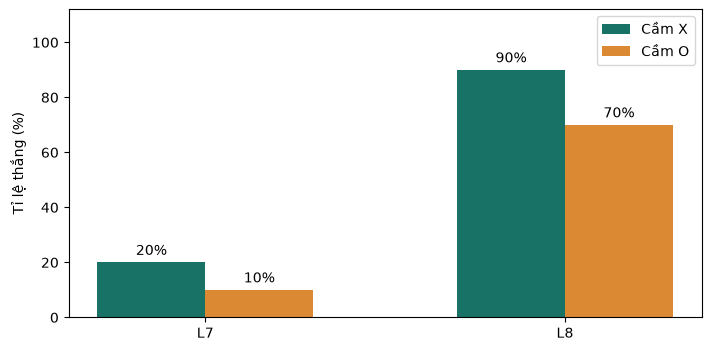

In [3]:
def record(label, result):
    n = len(result)
    counts = Counter(result)
    return {**label, "Ván": n, "Thắng": counts[1], "Hòa": counts[0], "Thua": counts[-1],
            "Tỉ lệ thắng": counts[1] / n, "Điểm": (counts[1] + 0.5 * counts[0]) / n}


format_pct = {"Tỉ lệ thắng": "{:.1%}", "Điểm": "{:.1%}"}

if games:
    pairs = defaultdict(dict)
    for r in games:
        if ({r["agent_x"], r["agent_o"]} != {"L7", "L8"} or r["result"] not in (-1, 0, 1)
                or r["moves"][:len(opening_map[r["opening_id"]])] != opening_map[r["opening_id"]]):
            raise ValueError(f"Log không hợp lệ tại ván {r['game_id']}.")
        pair = pairs[r["opening_id"]]
        if r["agent_x"] in pair:
            raise ValueError(f"Trùng màu tại khai cuộc {r['opening_id']}.")
        pair[r["agent_x"]] = r["result"]
    if not pairs or any(set(pair) != {"L7", "L8"} for pair in pairs.values()):
        raise ValueError("Mỗi khai cuộc phải có đủ hai ván đổi màu.")

    x_outcomes = np.array([[p["L7"], p["L8"]] for p in pairs.values()])
    outcomes = {("L7", "X"): x_outcomes[:, 0], ("L7", "O"): -x_outcomes[:, 1],
                ("L8", "X"): x_outcomes[:, 1], ("L8", "O"): -x_outcomes[:, 0]}

    by_agent = pd.DataFrame([record({"Tác tử": agent, "Màu": color}, result)
                             for (agent, color), result in outcomes.items()])
    by_color = pd.DataFrame([record({"Màu": "X"}, x_outcomes.ravel()), record({"Màu": "O"}, -x_outcomes.ravel())])
    display(by_agent.style.format(format_pct))
    display(by_color.style.format(format_pct))

    delta = ((x_outcomes == 1).astype(int) - (x_outcomes == -1)).mean(axis=1)
    print(f"Lợi thế thắng X − O: {100 * delta.mean():+.1f} điểm phần trăm trên {len(pairs)} khai cuộc.")
    if len(pairs) >= 2:
        samples = np.random.default_rng(99).choice(delta, size=(10_000, len(delta)), replace=True)
        lo, hi = np.quantile(samples.mean(axis=1), [0.025, 0.975])
        print(f"Khoảng bootstrap 95% theo khai cuộc: [{100 * lo:+.1f}; {100 * hi:+.1f}] điểm phần trăm.")

    fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
    for i, color in enumerate(("X", "O")):
        view = by_agent[by_agent["Màu"] == color]
        bars = ax.bar(np.arange(len(view)) + (i - 0.5) * 0.30, view["Tỉ lệ thắng"] * 100, 0.30,
                      label=f"Cầm {color}", color=("#187366", "#db8a33")[i])
        ax.bar_label(bars, fmt="%.0f%%", padding=3)
    ax.set(xticks=[0, 1], xticklabels=["L7", "L8"], ylim=(0, 112), ylabel="Tỉ lệ thắng (%)")
    ax.legend()
    plt.show()

### Soi nước đi chiến thuật

Mỗi ván được phát lại để tìm nước thắng ngay, nước phòng thủ duy nhất, nước tạo hai ô thắng và các lỗi bỏ lỡ thắng hoặc chặn
dù còn cách phòng thủ. Nếu đối thủ đã có nhiều ô thắng và không có nước cứu, notebook ghi nhận thế buộc thua ở nước kế
thay vì quy lỗi cho nước vừa đánh. Nhãn chỉ kiểm chứng chiến thuật một nước, vì vậy bỏ lỡ chiến thuật sâu vẫn có thể xảy ra.
Tọa độ ngang A–K, dọc 1–11. Trên bàn cờ, chữ thường đánh dấu nước thực tế và `+` đánh dấu nước thay thế.

In [4]:
def coord(move):
    return f"{chr(65 + move % N)}{1 + move // N}"


def audit(row, openings=None):
    opening = (opening_map if openings is None else openings)[row["opening_id"]]
    game = CaroGame.from_moves(opening)
    events = []
    for ply, move in enumerate(row["moves"][len(opening):], start=len(opening) + 1):
        mine, theirs = game.me_opp()
        win = set(iter_bits(winning_squares(mine, theirs)))
        threats = set(iter_bits(winning_squares(theirs, mine)))
        # Một nước của bên mình chỉ có thể vô hiệu hóa một ô thắng tức thì bằng cách chiếm ô đó.
        if move in win:
            label, severity, options = "Thắng ngay", 1, win
        elif win:
            label, severity, options = "Bỏ lỡ thắng ngay", 4, win
        elif len(threats) == 1 and move in threats:
            label, severity, options = "Chặn bắt buộc", 2, threats
        elif len(threats) == 1:
            label, severity, options = "Bỏ chặn, đối thủ có thể thắng ngay", 3, threats
        elif len(threats) > 1:
            label, severity, options = "Đã ở thế buộc thua ở nước kế", 0, set()
        else:
            placed = mine | (1 << move)
            forks = winning_squares(placed, theirs)
            if forks.bit_count() >= 2 and not winning_squares(theirs, placed):
                label, severity, options = "Tạo hai ô thắng ở lượt kế", 2, set()
            else:
                label = None
        if label:
            events.append({
                "Nước": ply, "Màu": "XO"[game.side], "Tác tử": row["agent_x" if game.side == 0 else "agent_o"],
                "Đã đi": coord(move), "Nhận xét": label,
                "Ô thay thế": ", ".join(map(coord, sorted(options - {move}))),
                "_severity": severity, "_move": move, "_options": options - {move},
            })
        game.step(move)
    if game.result() != row["result"]:
        raise ValueError(f"Kết quả khi phát lại khác log tại ván {row['game_id']}.")
    return events


def board_at(row, event):
    game = CaroGame.from_moves(row["moves"][:event["Nước"]])
    print("   " + " ".join(chr(65 + i) for i in range(N)))
    for r in range(N):
        symbols = []
        for c in range(N):
            pos = r * N + c
            if pos == event["_move"]:
                symbol = event["Màu"].lower()
            elif pos in event["_options"]:
                symbol = "+"
            else:
                symbol = next((s for side, s in enumerate("XO") if (game.bb[side] >> pos) & 1), ".")
            symbols.append(symbol)
        print(f"{r + 1:2} " + " ".join(symbols))


events_by_game = {r["game_id"]: audit(r) for r in games}
rows_by_id = {r["game_id"]: r for r in games}
errors = Counter(e["Tác tử"] for events in events_by_game.values() for e in events if e["_severity"] >= 3)
print("Số lần bỏ lỡ thắng/chặn ngay trong toàn bộ ván:", {a: errors[a] for a in ("L7", "L8")})
if CASE_IDS is None:
    def rank(r):
        severities = [e["_severity"] for e in events_by_game[r["game_id"]]]
        return sum(s >= 3 for s in severities), sum(s == 2 for s in severities)
    ranked = sorted(games, key=rank, reverse=True)
    picks = []
    used = set()
    for r in ranked:
        if r["opening_id"] not in used and len(picks) < N_CASES:
            picks.append(r["game_id"])
            used.add(r["opening_id"])
else:
    picks = CASE_IDS

for gid in picks:
    row = rows_by_id[gid]
    result = {1: "X thắng", -1: "O thắng", 0: "hòa"}[row["result"]]
    print(f"\nVán {gid} · khai cuộc {row['opening_id']} · X={row['agent_x']} · O={row['agent_o']} · {result}")
    events = events_by_game[gid]
    if not events:
        print("Không phát hiện tình huống chiến thuật một nước trong ván này.")
        continue
    # Ưu tiên lỗi có thể tránh và nước chặn; luôn giữ nước kết thúc nếu có.
    selected = sorted(events, key=lambda e: e["_severity"], reverse=True)[:6]
    final = next((e for e in reversed(events) if e["Nhận xét"] == "Thắng ngay"), None)
    if final is not None and final not in selected:
        selected[-1] = final
    display(pd.DataFrame([{k: v for k, v in e.items() if not k.startswith("_")}
                          for e in sorted(selected, key=lambda e: e["Nước"])]))
    key_event = max(selected, key=lambda e: e["_severity"])
    print(f"Bàn sau nước {key_event['Nước']} ({key_event['Đã đi']})")
    board_at(row, key_event)

Số lần bỏ lỡ thắng/chặn ngay trong toàn bộ ván: {'L7': 4, 'L8': 0}

Ván 13 · khai cuộc 48 · X=L7 · O=L8 · O thắng


,Nước,Màu,Tác tử,Đã đi,Nhận xét,Ô thay thế
0,12,O,L8,I10,Chặn bắt buộc,
1,19,X,L7,H5,Chặn bắt buộc,
2,22,O,L8,A3,Chặn bắt buộc,
3,24,O,L8,C7,Chặn bắt buộc,
4,35,X,L7,B5,"Bỏ chặn, đối thủ có thể thắng ngay",G4
5,36,O,L8,G4,Thắng ngay,


Bàn sau nước 35 (B5)
   A B C D E F G H I J K
 1 . . . . . . . . . . .
 2 . . X . . . X . . . .
 3 O . . O . O O . . . .
 4 . X . . O . + . . . .
 5 . x X O O O O X . . .
 6 . X O X X X O X . . .
 7 . X O X X X O X . . .
 8 . . . . O O X O . . .
 9 . . . . . . . X . . .
10 . . . . . . . . O . .
11 . . . . . . . . . . .

Ván 9 · khai cuộc 99 · X=L7 · O=L8 · O thắng


,Nước,Màu,Tác tử,Đã đi,Nhận xét,Ô thay thế
0,14,O,L8,F11,Chặn bắt buộc,
1,19,X,L7,B6,Chặn bắt buộc,
2,23,X,L7,F2,Chặn bắt buộc,
3,26,O,L8,C5,Chặn bắt buộc,
4,33,X,L7,E8,"Bỏ chặn, đối thủ có thể thắng ngay",G4
5,34,O,L8,G4,Thắng ngay,


Bàn sau nước 33 (E8)
   A B C D E F G H I J K
 1 . . . . O . . . . . .
 2 . . . . X X . . . . .
 3 . . . . X O . O . . .
 4 . . . X X O + . . . .
 5 . . O O X O O O . . .
 6 . X O O O O X O . . .
 7 . . . O X X X . . . .
 8 . . X X x X . . . . .
 9 . . . . . X . . . . .
10 . . . . . X . . . . .
11 . . . . . O . . . . .

Ván 2 · khai cuộc 10 · X=L8 · O=L7 · X thắng


,Nước,Màu,Tác tử,Đã đi,Nhận xét,Ô thay thế
0,15,X,L8,H11,Chặn bắt buộc,
1,19,X,L8,D11,Chặn bắt buộc,
2,22,O,L7,D2,Chặn bắt buộc,
3,24,O,L7,F7,"Bỏ chặn, đối thủ có thể thắng ngay",B6
4,25,X,L8,B6,Thắng ngay,


Bàn sau nước 24 (F7)
   A B C D E F G H I J K
 1 . . . . . . . . . . .
 2 . . . O . . . . . . .
 3 . . . . X . . . . . .
 4 . . . . . X . . . . .
 5 . . . . . . X . . . .
 6 . + X X X X O X . . .
 7 . . . O X o . . O . .
 8 . . . O O O X . . . .
 9 . . . O . O . . . . .
10 . . . O . . O . . . .
11 . . . X . . . X . . .


## 2. Arena L1–L8

Mặc định xem giải cũ; bạn có thể mở lại lượt mới bằng `READ_ARENA`. Khi bật `RUN_ARENA`, mọi cặp trong
`ARENA_LEVELS` dùng chung khai cuộc và đổi hai màu. Chạy thử với 1–2 khai cuộc trước:
8 tác tử tạo 28 cặp, tức **56 ván cho mỗi khai cuộc**. Dùng ít khai cuộc để kiểm tra notebook, dùng nhiều hơn
để so sánh sức chơi. Chọn danh sách rút gọn nếu chỉ cần xem L3, L7 và L8.

L3 dùng độ sâu cố định, L4/L7/L8 dùng số mô phỏng cố định. Các mốc này giữ nguyên giữa các ván trong một lượt.
Dùng bộ khai cuộc mới qua `OPENINGS_FILE` nếu cần tách dữ liệu khỏi các khai cuộc dùng lúc huấn luyện.

In [5]:
RUN_ARENA = False
READ_ARENA = None
ARENA_LEVELS = ("L1", "L2", "L3", "L4", "L5", "L6", "L7", "L8")
ARENA_N_OPENINGS = 2
ARENA_DEPTH = 6
ARENA_SIMS = 200
ARENA_PAIR = None              # ví dụ ("L7", "L8") khi xem một lượt có cả hai
ARENA_CASES = 3
ARENA_RUNS = ROOT / "runs/eval/arena_l1_l8"
ARCHIVE = ROOT / "runs/arena_matrix/games.csv"

AGENT_CONFIGS = {
    "L1": "l1_random", "L2": "l2_rule", "L3": "l3_alphabeta", "L4": "l4_mcts",
    "L5": "l5_policy_sl", "L6": "l6_policy_rl", "L7": "l7_puct", "L8": "l8_alphazero",
}

In [6]:
def run_arena():
    from itertools import combinations

    import torch
    from caro.agents import make_agent
    from caro.arena.match import play_match
    from caro.config import resolve_agent
    from caro.nn.model import CaroResNet
    from caro.training.train_pg import load_init

    pool = json.loads(OPENINGS_FILE.read_text(encoding="utf-8"))
    if not 1 <= ARENA_N_OPENINGS <= len(pool) or min(ARENA_DEPTH, ARENA_SIMS) < 1:
        raise ValueError("Số khai cuộc, độ sâu và số mô phỏng phải nằm trong giới hạn hợp lệ.")
    if len(ARENA_LEVELS) < 2 or len(set(ARENA_LEVELS)) != len(ARENA_LEVELS):
        raise ValueError("Chọn ít nhất hai cấp khác nhau.")
    device = torch.device(("cuda" if torch.cuda.is_available() else "cpu") if DEVICE == "auto" else DEVICE)
    if device.type == "cuda" and not torch.cuda.is_available():
        raise RuntimeError("Kernel hiện tại không truy cập được CUDA.")
    if device.type == "cpu":
        torch.set_num_threads(1)
    ids = np.random.default_rng(SEED).choice(len(pool), size=ARENA_N_OPENINGS, replace=False).tolist()
    used_openings = {i: pool[i] for i in ids}
    agents, specs, weights = {}, {}, {}
    for level in ARENA_LEVELS:
        spec = resolve_agent(f"agents/{AGENT_CONFIGS[level]}")
        spec["id"] = level
        spec["limits"] = {"mode": "fixed"}
        if level == "L3":
            spec["limits"]["max_depth"] = ARENA_DEPTH
        if level in ("L4", "L7", "L8"):
            spec["limits"]["max_sims"] = ARENA_SIMS
        if level == "L8" and L8_CHECKPOINT.is_file():
            spec["params"]["checkpoint"] = str(L8_CHECKPOINT)
        if level in ("L7", "L8"):
            spec["params"].update(backend=BACKEND, dirichlet=None, temperature=0.0)
        specs[level] = {**spec, "params": dict(spec["params"])}
        if level in ("L5", "L6", "L7", "L8"):
            model = CaroResNet().to(device)
            source = load_init(model, spec["params"].pop("checkpoint"), device)
            weights[level] = hashlib.sha256(Path(source).read_bytes()).hexdigest()
            spec["params"]["model"] = model
            if level in ("L5", "L6"):
                from caro.agents.base import Limits
                from caro.training.train_pg import NetAgent
                agents[level] = NetAgent(model, device, name=level)
                agents[level].limits = Limits.from_dict(spec["limits"])
                continue
        agents[level] = make_agent(spec)

    matchups = list(combinations(ARENA_LEVELS, 2))
    total = 2 * len(used_openings) * len(matchups)
    folder = ARENA_RUNS / datetime.now().strftime("%Y%m%d-%H%M%S-%f")
    folder.mkdir(parents=True)
    meta = {
        "expected": total, "seed": SEED, "device": str(device), "agents": list(ARENA_LEVELS),
        "specs": specs, "openings": used_openings, "opening_source": str(OPENINGS_FILE),
        "checkpoint_sha256": weights,
        "backends": {level: a.backend for level, a in agents.items() if hasattr(a, "backend")},
    }
    (folder / "meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    print(f"{total} ván · {device} · {folder.name}", flush=True)
    game_id = 0
    with (folder / "games.jsonl").open("x", encoding="utf-8") as log:
        for a, b in matchups:
            for opening_id, opening in used_openings.items():
                for x, o in [(a, b), (b, a)]:
                    row = play_match(agents[x], agents[o], opening, SEED, game_id)
                    fields = dict(game_id=game_id, opening_id=opening_id, agent_x=x, agent_o=o, plies=len(row["moves"]))
                    log.write(json.dumps({**row, **fields}) + "\n")
                    log.flush()
                    game_id += 1
            print(f"{game_id}/{total} ván · {a} gặp {b}", flush=True)
    return folder


arena_dir = run_arena() if RUN_ARENA else ARENA_RUNS / READ_ARENA if READ_ARENA else None
arena_openings = {}
if arena_dir is None:
    arena_games = pd.read_csv(ARCHIVE)
    arena_label = "Arena cũ · L1–L5"
    arena_names = sorted(set(arena_games["agent_x"]) | set(arena_games["agent_o"]))
else:
    arena_meta = json.loads((arena_dir / "meta.json").read_text(encoding="utf-8"))
    arena_openings = {int(key): moves for key, moves in arena_meta["openings"].items()}
    arena_games = pd.read_json(arena_dir / "games.jsonl", lines=True)
    if len(arena_games) != arena_meta["expected"]:
        raise ValueError(f"Lượt này chưa đủ ván: {len(arena_games)}/{arena_meta['expected']}.")
    arena_names = arena_meta["agents"]
    arena_label = f"Arena mới · {arena_dir.name}"
if not arena_games["result"].isin([-1, 0, 1]).all():
    raise ValueError("Có ván chưa kết thúc hoặc kết quả không hợp lệ.")
pair_counts = arena_games.groupby(["agent_x", "agent_o", "opening_id"]).size()
reversed_counts = pair_counts.reorder_levels([1, 0, 2])
if not pair_counts.eq(1).all() or not pair_counts.sort_index().equals(reversed_counts.sort_index()):
    raise ValueError("Mỗi cặp tác tử và khai cuộc cần đúng hai ván đổi màu.")
print(f"{arena_label} · {len(arena_games)} ván · {len(arena_names)} tác tử")

Arena cũ · L1–L5 · 1500 ván · 6 tác tử


### Bảng xếp hạng, ma trận đối đầu và thắng/hòa/thua

Điểm thắng 1, hòa 0,5, thua 0. Ô trong ma trận là điểm của tác tử ở hàng gặp tác tử ở cột.
Xếp hạng so sánh trong **cùng lượt arena**, với cùng tập đối thủ và ngân sách đã chọn.

,Tác tử,Ván,Thắng,Hòa,Thua,Tỉ lệ thắng,Điểm
0,L3 AB d3,500,404,1,95,80.8%,80.9%
1,L5 v2,500,369,4,127,73.8%,74.2%
2,L2 rule,500,327,2,171,65.4%,65.6%
3,L5 v1,500,296,1,203,59.2%,59.3%
4,L4 MCTS200,500,96,0,404,19.2%,19.2%
5,L1 random,500,4,0,496,0.8%,0.8%


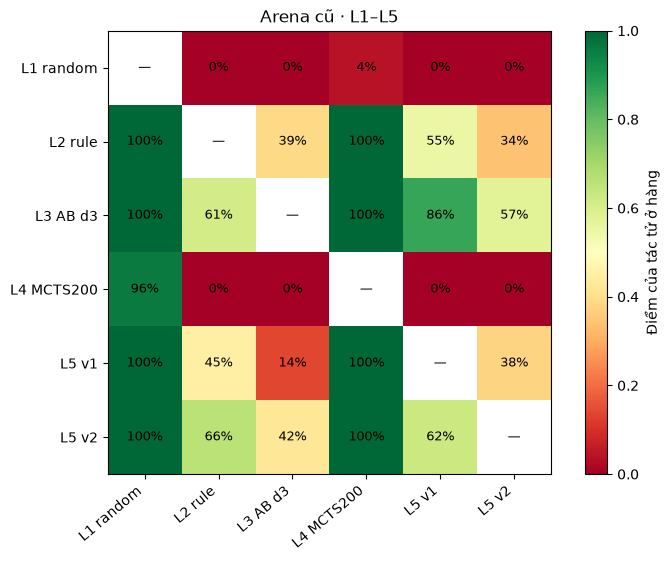

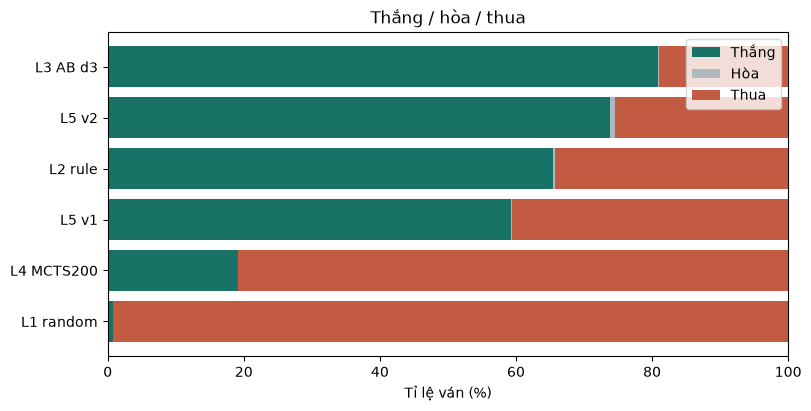

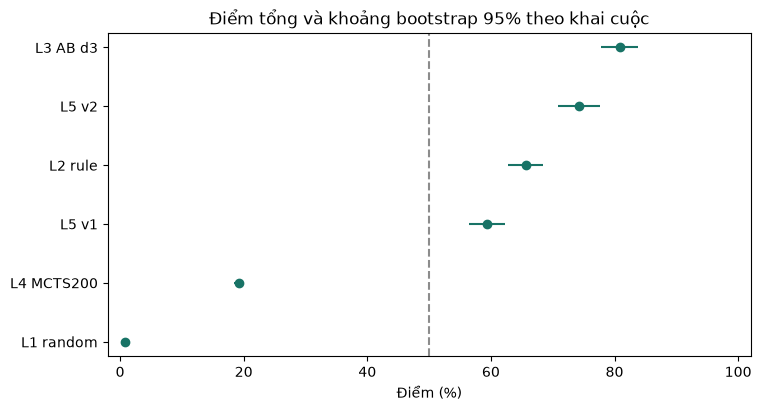

In [7]:
def orient_games(frame):
    rows = []
    for own, rival, color, sign in [("agent_x", "agent_o", "X", 1), ("agent_o", "agent_x", "O", -1)]:
        view = frame[["opening_id", own, rival, "result", "plies"]].rename(columns={own: "Agent", rival: "Opponent"})
        view = view.assign(Color=color, Outcome=sign * view["result"])
        rows.append(view.assign(Score=(view["Outcome"] + 1) / 2))
    return pd.concat(rows, ignore_index=True)


oriented = orient_games(arena_games)
ranking = pd.DataFrame([
    record({"Tác tử": name}, oriented.loc[oriented["Agent"] == name, "Outcome"])
    for name in arena_names
]).sort_values("Điểm", ascending=False).reset_index(drop=True)
display(ranking.style.format(format_pct))
matrix = oriented.pivot_table(index="Agent", columns="Opponent", values="Score").reindex(index=arena_names, columns=arena_names)

fig, ax = plt.subplots(figsize=(8, 5.5), layout="constrained")
heat = ax.imshow(matrix, vmin=0, vmax=1, cmap="RdYlGn")
for i, row in enumerate(matrix.to_numpy()):
    for j, score in enumerate(row):
        ax.text(j, i, "—" if np.isnan(score) else f"{score:.0%}", ha="center", va="center", fontsize=9)
ax.set(xticks=range(len(arena_names)), yticks=range(len(arena_names)), yticklabels=arena_names, title=arena_label)
ax.set_xticklabels(arena_names, rotation=40, ha="right")
fig.colorbar(heat, ax=ax, label="Điểm của tác tử ở hàng")
plt.show()

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
bottom = np.zeros(len(ranking))
for name, color in [("Thắng", "#187366"), ("Hòa", "#aeb8bf"), ("Thua", "#c35b42")]:
    pct = ranking[name] / ranking["Ván"] * 100
    ax.barh(ranking["Tác tử"], pct, left=bottom, label=name, color=color)
    bottom += pct.to_numpy()
ax.set(xlim=(0, 100), xlabel="Tỉ lệ ván (%)", title="Thắng / hòa / thua")
ax.invert_yaxis()
ax.legend()
plt.show()

# Bootstrap theo khai cuộc, lấy cả hai màu và mọi đối thủ của khai cuộc cùng nhau.
opening_scores = oriented.pivot_table(index="opening_id", columns="Agent", values="Score")
if len(opening_scores) >= 2 and not opening_scores.isna().any().any():
    names = ranking["Tác tử"].tolist()
    data = opening_scores[names].to_numpy()
    indices = np.random.default_rng(SEED).integers(0, len(data), size=(4_000, len(data)))
    lo, hi = np.quantile(data[indices].mean(axis=1), [.025, .975], axis=0)
    y = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(7.5, 4), layout="constrained")
    ax.hlines(y, lo * 100, hi * 100, color="#187366")
    ax.scatter(ranking["Điểm"] * 100, y, color="#187366")
    ax.set(yticks=y, yticklabels=names, xlim=(-2, 102), xlabel="Điểm (%)",
           title="Điểm tổng và khoảng bootstrap 95% theo khai cuộc")
    ax.axvline(50, ls="--", color="0.55")
    ax.invert_yaxis()
    plt.show()
else:
    print("Cần ít nhất hai khai cuộc chung để vẽ khoảng tin cậy của bảng xếp hạng.")

### X/O, độ dài ván và diễn biến của một cặp

Cột X/O đếm **tỉ lệ thắng thuần**; biểu đồ tích lũy dùng điểm và thêm mỗi lần một khai cuộc đủ hai màu.
Hộp độ dài tính theo số nước bao gồm khai cuộc. Log cũ thiếu thời gian từng nước nên phần thời gian chỉ xuất hiện với lượt mới.

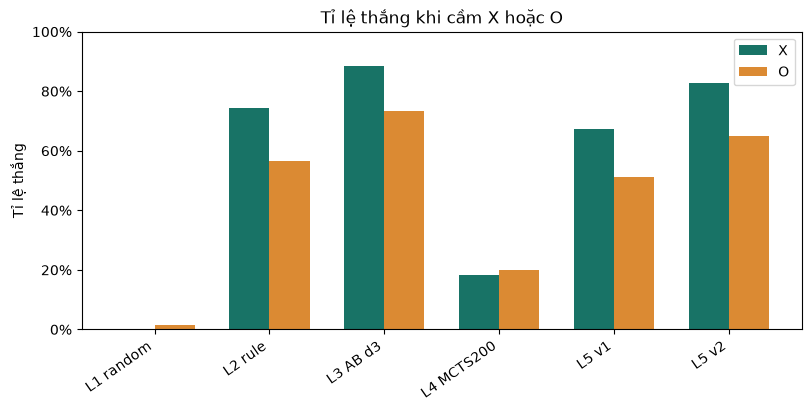

,Tác tử,Màu,Ván,Thắng,Hòa,Thua,Tỉ lệ thắng,Điểm
0,L5 v1,O,50,10,1,39,20.0%,21.0%
1,L5 v1,X,50,27,0,23,54.0%,54.0%
2,L5 v2,O,50,23,0,27,46.0%,46.0%
3,L5 v2,X,50,39,1,10,78.0%,79.0%


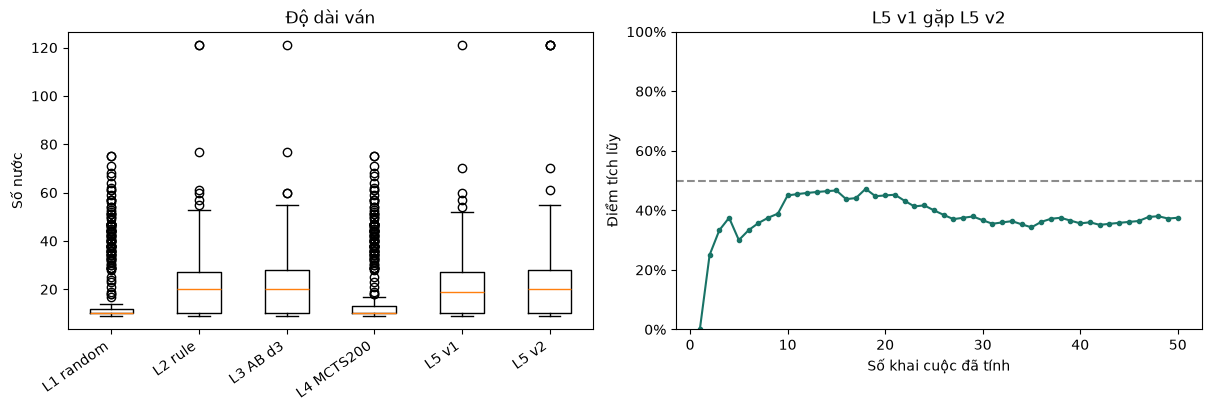

Lượt arena cũ chưa có thời gian theo nước.


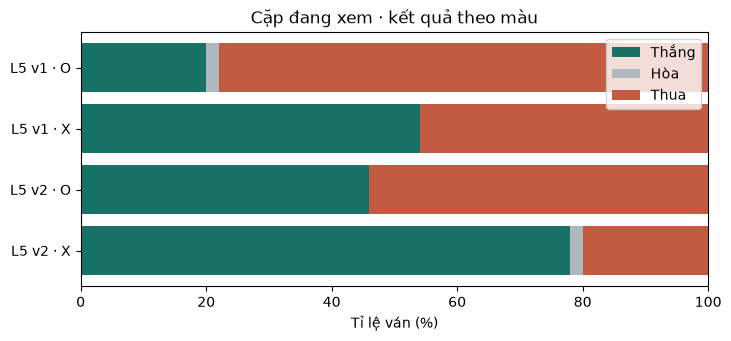

In [8]:
from matplotlib.ticker import PercentFormatter

by_side = (
    oriented.assign(Win=oriented["Outcome"] == 1)
    .pivot_table(index="Agent", columns="Color", values="Win").reindex(arena_names)
)
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for i, color in enumerate(("X", "O")):
    ax.bar(np.arange(len(arena_names)) + (i - .5) * .35, by_side[color], .35, label=color,
           color=("#187366", "#db8a33")[i])
ax.set(xticks=range(len(arena_names)), ylim=(0, 1), ylabel="Tỉ lệ thắng", title="Tỉ lệ thắng khi cầm X hoặc O")
ax.set_xticklabels(arena_names, rotation=35, ha="right")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.show()

pairs_arena = arena_games.assign(pair=arena_games.apply(
    lambda row: tuple(sorted((row["agent_x"], row["agent_o"]))), axis=1
))
view_pair = tuple(sorted(ARENA_PAIR)) if ARENA_PAIR else (
    ("L7", "L8") if {"L7", "L8"}.issubset(arena_names) else tuple(sorted(arena_names[-2:]))
)
view_games = pairs_arena.loc[pairs_arena["pair"].map(lambda pair: pair == view_pair)]
if view_games.empty:
    raise ValueError(f"Cặp {view_pair} chưa có trong lượt đang mở. Đổi ARENA_PAIR.")
view_table = pd.DataFrame([
    record({"Tác tử": agent, "Màu": color}, group["Outcome"])
    for (agent, color), group in orient_games(view_games).groupby(["Agent", "Color"])
])
display(view_table.style.format(format_pct))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].boxplot([oriented.loc[oriented["Agent"] == name, "plies"] for name in arena_names])
axes[0].set(xticks=range(1, len(arena_names) + 1), ylabel="Số nước", title="Độ dài ván")
axes[0].set_xticklabels(arena_names, rotation=35, ha="right")
a, b = view_pair
paired_score = orient_games(view_games).query("Agent == @a").groupby("opening_id")["Score"].mean().sort_index()
axes[1].plot(np.arange(1, len(paired_score) + 1), paired_score.expanding().mean(), marker="o", ms=3, color="#187366")
axes[1].axhline(.5, ls="--", color="0.55")
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(ylim=(0, 1), xlabel="Số khai cuộc đã tính", ylabel="Điểm tích lũy", title=f"{a} gặp {b}")
plt.show()

if "time_ms" in arena_games:
    timings = defaultdict(list)
    for row in arena_games.itertuples():
        first = len(arena_openings[row.opening_id]) % 2
        names = (row.agent_x, row.agent_o)
        for i, ms in enumerate(row.time_ms):
            timings[names[(first + i) % 2]].append(ms)
    quantiles = pd.DataFrame([
        {"Tác tử": name, "P50 ms": np.median(timings[name]), "P95 ms": np.quantile(timings[name], .95)}
        for name in arena_names if timings[name]
    ])
    display(quantiles.round(2))
    fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
    ax.barh(quantiles["Tác tử"], quantiles["P95 ms"], color="#346e98")
    ax.set(xlabel="P95 (ms/nước)", title="Thời gian suy nghĩ (95% số nước không vượt quá)")
    plt.show()
else:
    print("Lượt arena cũ chưa có thời gian theo nước.")

fig, ax = plt.subplots(figsize=(7.2, 3.3), layout="constrained")
labels = view_table["Tác tử"] + " · " + view_table["Màu"]
left = np.zeros(len(view_table))
for key, color in [("Thắng", "#187366"), ("Hòa", "#aeb8bf"), ("Thua", "#c35b42")]:
    share = view_table[key] / view_table["Ván"] * 100
    ax.barh(labels, share, left=left, color=color, label=key)
    left += share.to_numpy()
ax.set(xlim=(0, 100), xlabel="Tỉ lệ ván (%)", title="Cặp đang xem · kết quả theo màu")
ax.invert_yaxis()
ax.legend()
plt.show()

### Soi ván của cặp đang chọn

Lượt arena mới lưu toàn bộ nước đi. Phần này chọn vài ván của `ARENA_PAIR`, ưu tiên ván có sai lầm chiến thuật.
Lượt cũ chỉ có kết quả và số nước nên phần replay dùng bộ L7–L8 ở trên.

In [9]:
if arena_openings:
    cases = [(r, audit(r, arena_openings)) for r in view_games.to_dict("records")]
    cases.sort(key=lambda item: sum(e["_severity"] >= 3 for e in item[1]), reverse=True)
    seen_openings = set()
    for row, events in cases:
        if len(seen_openings) >= ARENA_CASES:
            break
        if row["opening_id"] in seen_openings:
            continue
        seen_openings.add(row["opening_id"])
        print(f"Ván {row['game_id']} · X={row['agent_x']} · O={row['agent_o']} · kết quả X={row['result']:+d}")
        if not events:
            print("Không có tình huống chiến thuật nằm trong các quy tắc kiểm tra.")
            continue
        selected = sorted(events, key=lambda e: e["_severity"], reverse=True)[:6]
        display(pd.DataFrame([{k: v for k, v in e.items() if not k.startswith("_")}
                              for e in sorted(selected, key=lambda e: e["Nước"])]))
        board_at(row, selected[0])
else:
    print("Xem mục 1 để phát lại các ván L7–L8 đã lưu.")

Xem mục 1 để phát lại các ván L7–L8 đã lưu.
